# 1. From an area to a network

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Khoshkhah/duckOSM/blob/main/docs/notebooks/01_area_to_network.ipynb) <a href="https://khoshkhah.github.io/duckOSM/notebooks/01_area_to_network.ipynb" download><img src="https://img.shields.io/badge/Download-notebook-F37626?logo=jupyter&logoColor=white" alt="Download the notebook"></a>

You choose an area on a map, get its OSM file, build the road network and query it with SQL.

| Step | Function |
|---|---|
| Choose the area and get its OSM file | `duckosm.AreaPicker`, `duckosm.get` |
| Build the network | `duckosm.build`: it gives a `duckosm.Network` |
| Draw the network | `net.map()` |
| Query the edges | `net.edges()`, `net.sql()` |

In [1]:
# Install duckOSM when it is not installed (for example in Colab). It takes approximately 1 minute.
try:
    import duckosm
except ImportError:
    %pip install -q "duckosm[widget]" roadstyle
    import duckosm
print("duckosm", duckosm.__version__)

duckosm 0.8.0


## Quick start

One call gets and builds an area. The cell shows the card of the network and its map. The sections after it do the same steps one at a time. Run the cell to see the live map: you can zoom, and click a road to see its columns. This page shows a picture of the map.

In [2]:
net = duckosm.network("Monaco")    # get and build Monaco in one call: a duckosm.Network
net                                # the card: the file, and the edges, nodes and km of each mode

cut: 34794 nodes, 5693 ways, 343 relations

Output: data/monaco.duckdb

mode,edges,nodes,km
driving,"2,840","1,768",96.2


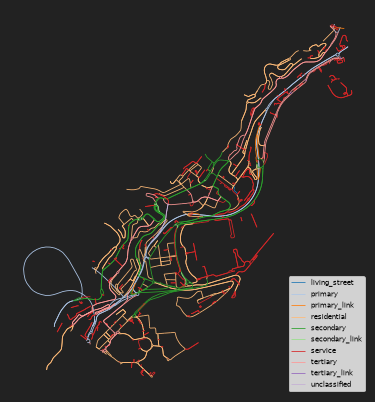

In [3]:
net.map(theme="dark")    # roadstyle's road look on a dark base map: one color for each road class

## Choose the area

The widget shows a map. Choose an area with one of the tabs (Search, OSM id, Box, H3 cell, File), then click **Get**. The line under the map shows the Geofabrik extract and its size before the download.

If you do not choose an area, the notebook uses Monaco. The guide is [Choose an area in Jupyter](https://khoshkhah.github.io/duckOSM/guides/area-picker/).

![The AreaPicker widget: the search found Monaco](https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/images/area-picker.png)

In [4]:
picker = duckosm.AreaPicker(out="data")              # the files go into the folder data/
picker.area = {"mode": "place", "place": "Monaco"}   # the area when you choose none on the map
picker

## Get the OSM file

`picker.get()` downloads the extract (when it is not in the cache) and cuts it to the boundary. If you clicked **Get**, the cell waits for that run.

In [5]:
area = picker.result or picker.get()   # the result of Get, or get it now
area                                   # two paths: the .osm.pbf file and the boundary

boundary: Monaco, OSM relation 1124039, 79.8 km², from Nominatim

,file,size
OSM file,data/monaco.osm.pbf,0.6 MB
boundary,data/monaco.geojson,13 kB


## Build the network

`duckosm.build` writes one DuckDB file with one schema for each mode, and gives a `duckosm.Network`. Monaco takes some seconds.

In [6]:
name = area.pbf.name.split(".")[0]    # "monaco"
net = duckosm.build(pbf=area.pbf, boundary=area.boundary, modes=["driving", "walking"], output=f"data/{name}.duckdb")
net                                   # the card of the new network

Output: data/monaco.duckdb

mode,edges,nodes,km
driving,"2,840","1,768",96.2
walking,"11,938","4,589",260.6


## Draw the network

Run the cell to see the live map: you can zoom, and click a road to see its columns. This page shows a picture of the map.

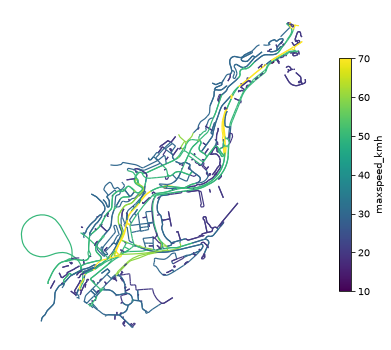

In [7]:
net.map(color_by="maxspeed_kmh", cmap="viridis")    # the driving network, colored by the speed limit

## Query the edges

Each row of `<mode>.edges` is one direction of a road. `edge_id` is a `BIGINT` content hash: it stays the same after a rebuild, a cut and an export. Other data joins on it (see notebook 5).

In [8]:
from IPython.display import HTML    # to show a table with no index column and no NaN

HTML(net.columns("driving").head(8).to_html(index=False))    # the first columns of driving.edges and their types

column_name,column_type
edge_id,BIGINT
edge_ref,VARCHAR
source,BIGINT
target,BIGINT
osm_id,BIGINT
highway,VARCHAR
name,VARCHAR
oneway,BOOLEAN


In [9]:
edges = net.edges()    # the driving edges as a GeoDataFrame
HTML(edges[["edge_id", "name", "highway", "length_m", "maxspeed_kmh"]].head().round(1).to_html(index=False, na_rep=""))

edge_id,name,highway,length_m,maxspeed_kmh
414242052250797,Boulevard du Ténao,residential,44.2,30.0
2214154189574909,,service,24.3,20.0
15757195119014288,Rue du Ténao,residential,9.1,30.0
16871577064511426,,residential,4.0,30.0
21502429769987032,,residential,3.6,30.0


In [10]:
# the number of edges and the length of each network
HTML(net.sql("""SELECT 'driving' AS mode, count(*) AS edges, round(sum(length_m) / 1000, 1) AS km FROM driving.edges
           UNION ALL
           SELECT 'walking', count(*), round(sum(length_m) / 1000, 1) FROM walking.edges""").to_html(index=False, na_rep=""))

mode,edges,km
driving,2840,96.2
walking,11938,260.6


In [11]:
# the road classes of the driving network, by length
HTML(net.sql("""SELECT highway, count(*) AS edges, round(sum(length_m) / 1000, 1) AS km
           FROM driving.edges GROUP BY highway ORDER BY km DESC LIMIT 8""").to_html(index=False, na_rep=""))

highway,edges,km
residential,919,31.7
service,855,23.7
secondary,429,14.9
tertiary,387,12.5
primary,197,11.2
primary_link,21,1.1
unclassified,13,0.6
secondary_link,13,0.4


In [12]:
# the longest named roads, and the type of edge_id
HTML(net.sql("""SELECT name, round(sum(length_m)) AS length_m, count(*) AS edges, any_value(typeof(edge_id)) AS edge_id_type
           FROM driving.edges WHERE name IS NOT NULL GROUP BY name ORDER BY length_m DESC LIMIT 5""").to_html(index=False, na_rep=""))

name,length_m,edges,edge_id_type
Boulevard du Larvotto,5305.0,85,BIGINT
Boulevard du Jardin Exotique,3280.0,73,BIGINT
Avenue Princesse Grace,2576.0,86,BIGINT
Avenue Pasteur,2246.0,42,BIGINT
Tunnel Albert II,1994.0,7,BIGINT
